In [ ]:
import random
import numpy as np
import pandas as pd

# 划分训练集与测试集
from sklearn.model_selection import train_test_split
# 标准化
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
# 优化器
import torch.optim as optim

In [14]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']
plt.rcParams['figure.dpi'] = 150   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

In [ ]:
# 设置随机种子
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [ ]:
# 导入数据、定义列名
data = pd.read_csv('iris.txt', header = None)
data.columns = ['sepal length','sepal width','petal length','petal width','class']
# 查看数据前5行
print(data.iloc[0:5, :])
print(set(data['class']))
print(len(data))

   sepal length  sepal width  petal length  petal width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
{'Iris-setosa', 'Iris-virginica', 'Iris-versicolor'}
150


In [17]:
# 定义特征
X = data.iloc[:,0:4].values.astype(float)

# 标签的类别字符串 转变为 整数
data['class'] = data['class'].replace({
    'Iris-setosa': 0,
    'Iris-versicolor': 1,
    'Iris-virginica': 2
})

# 定义标签
y = data.iloc[:,4].values.astype(int)

# 划分训练集与测试集为120:30
train_X, test_X, train_y, test_y = train_test_split(
    X, y, 
    train_size=0.8, 
    test_size=0.2, 
    random_state=0
)

# 在训练集中，再划分训练集与验证集为100:20
train_X, val_X, train_y, val_y = train_test_split(
    train_X, train_y,
    test_size=20,
    random_state=0,
    stratify=train_y
)

In [18]:
scaler = StandardScaler()

# 学习训练集的均值与标准差后，转换训练集数据
train_X = scaler.fit_transform(train_X)
# 使用训练集的均值与标准差，转换验证集、测试集数据（防止数据泄漏）
val_X = scaler.transform(val_X)
test_X = scaler.transform(test_X)

print(train_X[0:5, :])

[[-0.09538271 -0.82836952  0.69869453  0.86020096]
 [ 1.16872544  0.13765907  0.8654474   1.11851956]
 [-1.35949085  0.37916622 -1.4135085  -1.33550719]
 [-1.01473408  0.37916622 -1.46909279 -1.33550719]
 [-1.01473408 -2.51891955 -0.19065412 -0.30223277]]


In [19]:
# 将数据转换为pytorch的张量
train_X_tensor = torch.tensor(train_X, dtype = torch.float32)
val_X_tensor = torch.tensor(val_X, dtype = torch.float32)
test_X_tensor = torch.tensor(test_X, dtype = torch.float32)

train_y_tensor = torch.tensor(train_y, dtype = torch.long)
val_y_tensor = torch.tensor(val_y, dtype = torch.long)
test_y_tensor = torch.tensor(test_y, dtype = torch.long)

In [20]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 16) # 输入层 4 -> 隐层1 16
        self.fc2 = nn.Linear(16, 16) # 隐层1 16 -> 隐层2 16
        self.out = nn.Linear(16, 3) # 隐层2 16 -> 输出层 3
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.out(x)  # 直接输出线性结果
        return x
    

In [21]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.Adam(model.parameters(), lr = 0.001) # 优化器

In [22]:
model.train() # 将模型切换到训练状态

epochs = 1000
result_history = []

for epoch in range(epochs):
    optimizer.zero_grad() # 梯度清零
    preds_train_y = model(train_X_tensor) # 前向传播
    loss_train = criterion(preds_train_y, train_y_tensor) # 计算损失
    loss_train.backward() # 反向传播（自动求导 并 累加梯度）
    optimizer.step() # 根据求导计算出的 梯度，更新模型参数

    with torch.no_grad():
        # 统计验证集情况
        preds_val_y = model(val_X_tensor) 
        loss_val = criterion(preds_val_y, val_y_tensor)

        predicted_classes = torch.argmax(preds_val_y, dim=1)
        correct = (predicted_classes == val_y_tensor).sum().item()
        accuracy = correct / val_y_tensor.size(0)
    
    result_history.append([loss_train.item(), accuracy, loss_val.item()]) # 记录损失
    
    print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {loss_train.item():.4f}, 验证集Acc: {accuracy:.4f}, 验证集loss: {loss_val.item():.4f}")

训练进度: 1/1000, 训练集loss: 1.0934, 验证集Acc: 0.3000, 验证集loss: 1.1030
训练进度: 2/1000, 训练集loss: 1.0898, 验证集Acc: 0.3000, 验证集loss: 1.0998
训练进度: 3/1000, 训练集loss: 1.0863, 验证集Acc: 0.3000, 验证集loss: 1.0966
训练进度: 4/1000, 训练集loss: 1.0828, 验证集Acc: 0.3000, 验证集loss: 1.0935
训练进度: 5/1000, 训练集loss: 1.0793, 验证集Acc: 0.3000, 验证集loss: 1.0904
训练进度: 6/1000, 训练集loss: 1.0759, 验证集Acc: 0.3000, 验证集loss: 1.0872
训练进度: 7/1000, 训练集loss: 1.0725, 验证集Acc: 0.3000, 验证集loss: 1.0840
训练进度: 8/1000, 训练集loss: 1.0692, 验证集Acc: 0.3000, 验证集loss: 1.0807
训练进度: 9/1000, 训练集loss: 1.0658, 验证集Acc: 0.3000, 验证集loss: 1.0774
训练进度: 10/1000, 训练集loss: 1.0626, 验证集Acc: 0.3500, 验证集loss: 1.0742
训练进度: 11/1000, 训练集loss: 1.0593, 验证集Acc: 0.4500, 验证集loss: 1.0710
训练进度: 12/1000, 训练集loss: 1.0561, 验证集Acc: 0.4500, 验证集loss: 1.0678
训练进度: 13/1000, 训练集loss: 1.0529, 验证集Acc: 0.5000, 验证集loss: 1.0646
训练进度: 14/1000, 训练集loss: 1.0496, 验证集Acc: 0.5000, 验证集loss: 1.0615
训练进度: 15/1000, 训练集loss: 1.0464, 验证集Acc: 0.6000, 验证集loss: 1.0583
训练进度: 16/1000, 训练集loss: 1.0431, 验证集Acc: 0.6000, 验

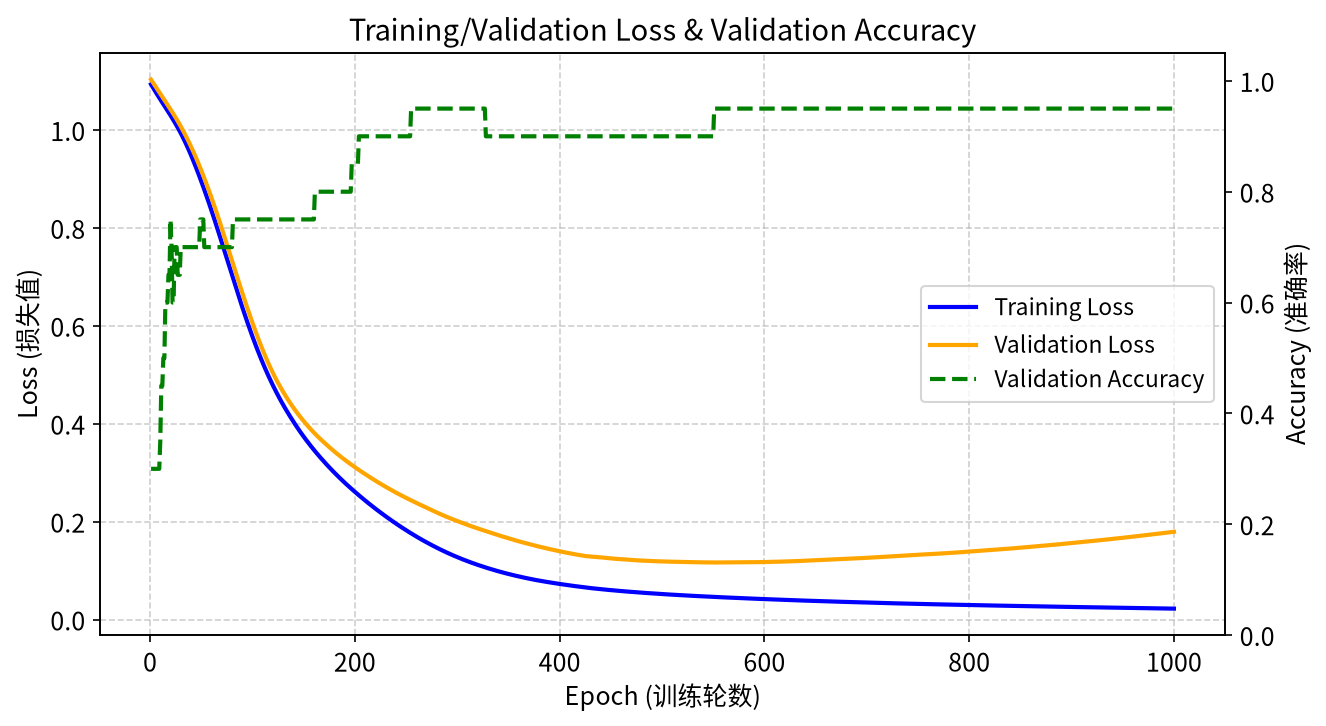

In [23]:
# 将 result_history 转为 numpy
history = np.array(result_history)
epochs_range = range(1, len(history) + 1)

fig, ax1 = plt.subplots(figsize=(9, 5))

# 左轴：训练损失 + 验证损失
line1, = ax1.plot(epochs_range, history[:, 0], label='Training Loss', color='blue', linewidth=2)
line2, = ax1.plot(epochs_range, history[:, 2], label='Validation Loss', color='orange', linewidth=2)
ax1.set_xlabel('Epoch (训练轮数)', fontsize=12)
ax1.set_ylabel('Loss (损失值)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.6)

# 右轴：验证准确率
ax2 = ax1.twinx()
line3, = ax2.plot(epochs_range, history[:, 1], label='Validation Accuracy',
                  color='green', linewidth=2, linestyle='--')
ax2.set_ylabel('Accuracy (准确率)', fontsize=12)
ax2.set_ylim(0, 1.05)

# 合并两个 y 轴的图例
lines = [line1, line2, line3]
ax1.legend(lines, [l.get_label() for l in lines], loc='center right', fontsize=11)

plt.title('Training/Validation Loss & Validation Accuracy', fontsize=14)
plt.tight_layout()
plt.show()

In [24]:
model.eval() # 将模型切换到测试状态

with torch.no_grad(): # 关闭梯度计算
    test_preds = model(test_X_tensor)
    test_loss = criterion(test_preds, test_y_tensor)
    predicted_classes = torch.argmax(test_preds, dim=1)
    correct = (predicted_classes == test_y_tensor).sum().item()

    accuracy = correct / test_y_tensor.size(0)

print(f"测试集损失 (Test Loss): {test_loss.item():.4f}")
print(f"测试集准确率 (Test Accuracy): {accuracy * 100:.2f}%  ({correct}/{test_y_tensor.size(0)})")

测试集损失 (Test Loss): 0.0507
测试集准确率 (Test Accuracy): 96.67%  (29/30)
